# 00 · Probability, tensors and Gaussian corruption

Follow signal, noise, density and score on a distribution we can evaluate exactly, before introducing a network.

**Prerequisites:** Python functions, vectors, Gaussian moments and derivatives.

**By the end:** Broadcast coefficients; distinguish a marginal coupling from an SDE; compare schedules and derive corrupted moments.

Run from top to bottom. Default experiments use CPU, fixed seeds and no downloads. Small trained models illustrate learning; analytic oracles isolate mathematical and solver effects. Neither is an image-quality benchmark.

[Course index](README.md) · [Notation](../docs/23_notation_and_code.md) · [Implementation scope](../docs/15_coverage_and_scope.md)

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import Image, display

project = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "diffusion_lab").is_dir())
if str(project) not in sys.path:
    sys.path.insert(0, str(project))
torch.set_num_threads(2)
torch.manual_seed(7)
np.random.seed(7)
plt.rcParams.update(
    {
        "figure.figsize": (10, 3.6),
        "axes.spines.top": False,
        "axes.spines.right": False,
        "figure.dpi": 100,
    }
)
ENABLE_WIDGETS = False  # Set True in Jupyter; static figures work on GitHub.
print(f"PyTorch {torch.__version__}; CPU lesson; seed=7; no automatic downloads.")


def scatter(ax, samples, title, labels=None, limits=(-4.5, 4.5)):
    points = samples.detach().cpu().numpy()
    colors = labels.detach().cpu().numpy() if labels is not None else "steelblue"
    ax.scatter(
        points[:, 0],
        points[:, 1],
        c=colors,
        cmap="tab10" if labels is not None else None,
        s=5,
        alpha=0.55,
        linewidths=0,
    )
    ax.set(title=title, xlabel="$x_1$", ylabel="$x_2$", aspect="equal", xlim=limits, ylim=limits)


def saved_gallery(relative, caption):
    path = project / relative
    if not path.is_file():
        raise FileNotFoundError(f"Missing curated course evidence: {relative}")
    print(caption)
    display(Image(filename=str(path)))


def animate_particles(history, name, title, labels=None, limits=(-4.5, 4.5)):
    from matplotlib.animation import FuncAnimation, PillowWriter

    points = history.detach().cpu().numpy()
    indices = np.linspace(0, len(points) - 1, min(32, len(points))).astype(int)
    fig, ax = plt.subplots(figsize=(4.5, 4.5))
    colors = labels.detach().cpu().numpy() if labels is not None else "steelblue"
    dots = ax.scatter(
        *points[0].T,
        c=colors,
        cmap="tab10" if labels is not None else None,
        s=9,
        alpha=0.65,
        linewidths=0,
    )
    ax.set(xlim=limits, ylim=limits, aspect="equal", xlabel="$x_1$", ylabel="$x_2$")

    def update(frame):
        dots.set_offsets(points[indices[frame]])
        ax.set_title(f"{title}: frame {frame + 1}/{len(indices)}")
        return (dots,)

    animation = FuncAnimation(fig, update, frames=len(indices), interval=100)
    folder = project / "assets/teaching/notebooks"
    folder.mkdir(parents=True, exist_ok=True)
    target = folder / f"{name}.gif"
    animation.save(target, writer=PillowWriter(fps=10), dpi=75)
    plt.close(fig)
    display(Image(filename=str(target)))

PyTorch 2.7.1+cu128; CPU lesson; seed=7; no automatic downloads.


## 1. Samples, densities and scores

Our data law is $p_0(x)=K^{-1}\sum_k\mathcal N(x;\mu_k,s_0^2 I)$.
A sample has shape `[B,2]`, means `[K,2]`, and `log_prob(x)` returns `[B]`.
The score $\nabla_x\log p(x)$ has the **same shape as x**, not the shape of a probability.
Labels identify sampled components; real datasets need not expose such labels.
**Equation → code:** `GaussianMixture.sample`, `.log_prob`, `.score` in [data.py](../diffusion_lab/data.py).

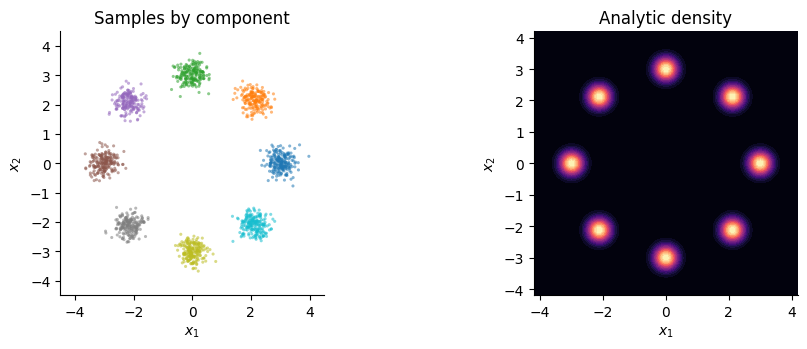

sample / label / density shapes: torch.Size([1600, 2]) torch.Size([1600]) torch.Size([1600])


In [2]:
from diffusion_lab.data import GaussianMixture
from diffusion_lab.paths import GaussianPath, expand

mixture = GaussianMixture(components=8, radius=3, std=0.25)
generator = torch.Generator().manual_seed(7)
clean, labels = mixture.sample(1600, generator)
grid = torch.linspace(-4.2, 4.2, 100)
yy, xx = torch.meshgrid(grid, grid, indexing="ij")
points = torch.stack([xx.flatten(), yy.flatten()], dim=1)
density = mixture.log_prob(points).exp().reshape(100, 100)
fig, axes = plt.subplots(1, 2)
scatter(axes[0], clean, "Samples by component", labels)
axes[1].contourf(xx, yy, density, levels=24, cmap="magma")
axes[1].set(title="Analytic density", aspect="equal", xlabel="$x_1$", ylabel="$x_2$")
plt.tight_layout()
plt.show()
print("sample / label / density shapes:", clean.shape, labels.shape, mixture.log_prob(clean).shape)

## 2. Corruption and broadcasting

Diffusion time increases **data → noise**:
$$X_t=\alpha(t)X_0+\sigma(t)\epsilon,\qquad\epsilon\sim\mathcal N(0,I),\quad\epsilon\perp X_0.$$
$\sigma$ is a standard deviation, not variance. `t`, `alpha`, `sigma` have shape `[B]`.
`expand(alpha,x)` returns `[B,1]` for points or `[B,1,1,1]` for images `[B,C,H,W]`.
The conditional law is $q_t(x|x_0)=\mathcal N(\alpha x_0,\sigma^2I)$;
the marginal $p_t$ averages it over data.
**Code:** `GaussianPath.coefficients`, `expand` in [paths.py](../diffusion_lab/paths.py).

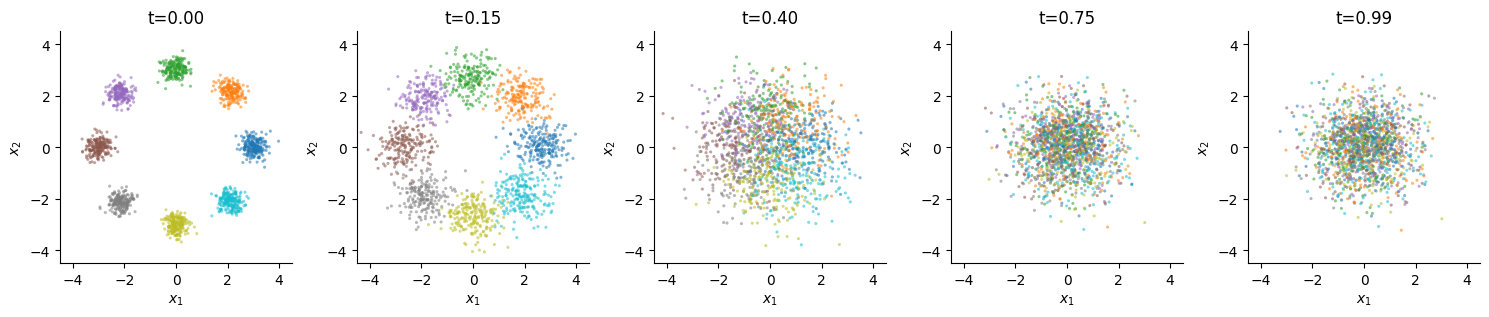

In [3]:
noise = torch.randn(clean.shape, generator=generator)
path = GaussianPath("vp_linear")
times = [0.0, 0.15, 0.4, 0.75, 0.99]
fig, axes = plt.subplots(1, len(times), figsize=(15, 3))
for ax, time in zip(axes, times, strict=True):
    a, s = path.coefficients(torch.full((len(clean),), time))
    scatter(ax, expand(a, clean) * clean + expand(s, clean) * noise, f"t={time:.2f}", labels)
plt.tight_layout()
plt.show()
assert expand(torch.ones(4), torch.zeros(4, 3, 16, 16)).shape == (4, 1, 1, 1)

## 3. Different schedules, different paths

For VP, $\alpha^2+\sigma^2=1$. With $B(t)=\int_0^t\beta(s)ds$,
$\alpha=e^{-B/2}$, $\sigma=\sqrt{1-e^{-B}}$. Linear **beta** is not linear noise.
Sub-VP uses $\sigma=1-e^{-B}$. VE uses $\alpha=1$ and
$\sigma=\sigma_{\min}(\sigma_{\max}/\sigma_{\min})^t$.
Here `vp_exponential` means constant beta/exponentially decaying signal;
`vp_logsnr` linearly interpolates $\log(\alpha^2/\sigma^2)$.
VE starts with small smoothing; finite log-SNR bounds give approximate endpoints.
The cosine SDE is singular at $t=1$; evaluate its field inside the interval.

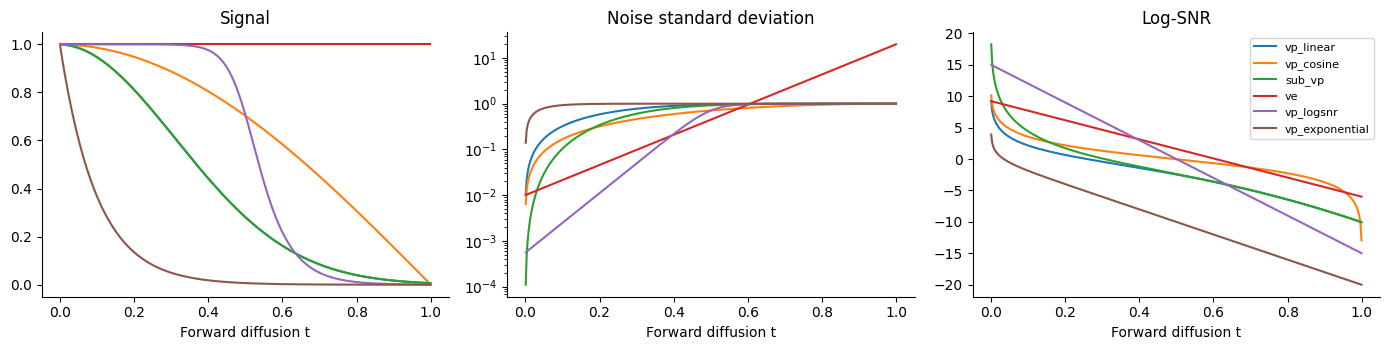

In [4]:
grid = torch.linspace(0.001, 0.999, 400)
kinds = ["vp_linear", "vp_cosine", "sub_vp", "ve", "vp_logsnr", "vp_exponential"]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for kind in kinds:
    a, s = GaussianPath(kind).coefficients(grid)
    axes[0].plot(grid, a, label=kind)
    axes[1].plot(grid, s, label=kind)
    axes[2].plot(grid, 2 * (a.log() - s.log()), label=kind)
for ax, title in zip(axes, ["Signal", "Noise standard deviation", "Log-SNR"], strict=True):
    ax.set(title=title, xlabel="Forward diffusion t")
axes[1].set_yscale("log")
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 4. Check the moments

Independence implies $\mathbb E[X_t]=\alpha\mathbb E[X_0]$ and
$\operatorname{Cov}(X_t)=\alpha^2\operatorname{Cov}(X_0)+\sigma^2I$.
VP preserves **unit Gaussian variance**, not every dataset's variance.

In [5]:
g = torch.Generator().manual_seed(11)
x0 = 2 * torch.randn(100000, 1, generator=g) + 3
eps = torch.randn(x0.shape, generator=g)
a, s = GaussianPath().coefficients(torch.tensor([0.25]))
xt = a * x0 + s * eps
expected_mean, expected_variance = 3 * a.item(), 4 * a.square().item() + s.square().item()
print(
    {
        "empirical_mean": xt.mean().item(),
        "analytic_mean": expected_mean,
        "empirical_variance": xt.var().item(),
        "analytic_variance": expected_variance,
    }
)
assert abs(xt.mean().item() - expected_mean) < 0.03
assert abs(xt.var().item() - expected_variance) < 0.05

{'empirical_mean': 2.167285203933716, 'analytic_mean': 2.1709715723991394, 'empirical_variance': 2.543668031692505, 'analytic_variance': 2.571039229631424}


## 5. Watch the marginal change

We reuse one noise vector per point: a **coupling of marginal samples**, not
a forward SDE trajectory. The time marginals are correct but the joint law across times differs.
The animation is also saved as a standalone [GIF](../assets/teaching/notebooks/00_gaussian_corruption.gif).

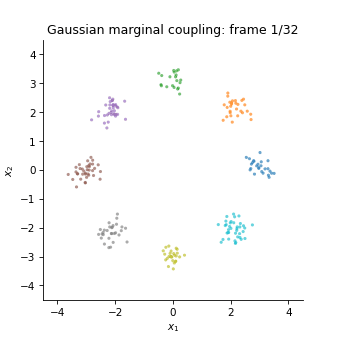

In [6]:
history = []
for time in torch.linspace(0, 0.99, 32):
    a, s = path.coefficients(time.repeat(240))
    history.append(expand(a, clean[:240]) * clean[:240] + expand(s, clean[:240]) * noise[:240])
animate_particles(
    torch.stack(history), "00_gaussian_corruption", "Gaussian marginal coupling", labels[:240]
)

In [7]:
def explore_noising(time=0.4, schedule="vp_linear"):
    a, s = GaussianPath(schedule).coefficients(torch.full((len(clean),), float(time)))
    _fig, ax = plt.subplots()
    scatter(
        ax, expand(a, clean) * clean + expand(s, clean) * noise, f"{schedule}, t={time:.2f}", labels
    )
    plt.show()


if ENABLE_WIDGETS:
    from ipywidgets import interact

    interact(explore_noising, time=(0.01, 0.99, 0.02), schedule=kinds)

## Exercises and worked answers

1. For $X_0\sim\mathcal N(3,4)$, find the corrupted mean/variance. What variance does VP preserve?
2. Why would fresh independent noise at every animation frame not produce an SDE trajectory?
3. Change component radius and standard deviation. Which ratio controls visible mode separation?

<details><summary>Worked answers</summary>

1. Mean $3\alpha$, variance $4\alpha^2+\sigma^2$. VP preserves variance 1.
2. Brownian increments have variance proportional to $dt$; independent marginal redraws impose a different temporal covariance.
3. Separation scales with $\alpha\|\mu_i-\mu_j\|/\sqrt{\alpha^2s_0^2+\sigma^2}$, rather than time alone.

</details>

**Continue:** [DDPM/DDIM](01_prediction_targets_and_ddim.ipynb).
**Read:** [Foundations](../docs/01_foundations.md), [SDE paper](https://arxiv.org/abs/2011.13456).